<h1>Oil Shocks, Interest Rates, and Crowding Out <small style="font-size:0.45em; color:#666; vertical-align:middle;">Supplemental Code</small></h1>

## 1. Setup and dependencies

In [1]:
# Standard scientific Python stack
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Reproducible plot style — navy/teal palette
NAVY, TEAL, ORANGE, RED, GRAY = '#1f3a5f', '#2e8b8b', '#d97706', '#c1272d', '#6b7280'
plt.rcParams.update({
    'font.family': 'serif', 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.edgecolor': '#333', 'axes.linewidth': 0.8,
    'grid.color': '#dddddd', 'grid.linewidth': 0.4,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})

print('Setup complete')


Setup complete


## 2. Data acquisition

### 2.1 Market data from Yahoo Finance

In [2]:
# pip install yfinance if not already installed
import yfinance as yf

tickers = {
    'CL=F':  'WTI Crude Oil Futures',
    '^GSPC': 'S&P 500',
    '^TNX':  '10-Year Treasury Yield',
    'BZ=F':  'Brent Crude',
}

market_data = {}
for ticker, name in tickers.items():
    df = yf.download(ticker, start='2000-01-01', end='2026-05-09', progress=False, auto_adjust=True)
    market_data[ticker] = df['Close']
    print(f'{ticker:<8} {name:<28} {len(df):>5} rows  ({df.index.min().date()} → {df.index.max().date()})')


CL=F     WTI Crude Oil Futures         6455 rows  (2000-08-23 → 2026-05-08)
^GSPC    S&P 500                       6627 rows  (2000-01-03 → 2026-05-08)
^TNX     10-Year Treasury Yield        6621 rows  (2000-01-03 → 2026-05-08)
BZ=F     Brent Crude                   4673 rows  (2007-07-30 → 2026-05-08)


### 2.2 U.S. macro data from World Bank API

In [4]:
import requests

wb_indicators = {
    'FP.CPI.TOTL.ZG':    'Inflation, consumer prices (annual %)',
    'GC.DOD.TOTL.GD.ZS': 'Central government debt, total (% of GDP)',
    'NE.GDI.TOTL.ZS':    'Gross capital formation (% of GDP)',
    'NY.GDP.MKTP.KD.ZG': 'GDP growth (annual %)',
    'GC.XPN.TOTL.GD.ZS': 'Gen government expense (% of GDP)',
}

us_macro = pd.DataFrame()
for code, name in wb_indicators.items():
    url = f'https://api.worldbank.org/v2/country/USA/indicator/{code}?date=2000:2024&format=json&per_page=100'
    r = requests.get(url, timeout=60).json()
    if len(r) > 1 and r[1]:
        vals = pd.DataFrame([(int(x['date']), x['value']) for x in r[1] if x['value'] is not None],
                            columns=['year', code]).sort_values('year').set_index('year')
        us_macro = vals if us_macro.empty else us_macro.join(vals, how='outer')

us_macro = us_macro.rename(columns={
    'FP.CPI.TOTL.ZG': 'Inflation_pct',
    'GC.DOD.TOTL.GD.ZS': 'Debt_GDP_pct',
    'NE.GDI.TOTL.ZS': 'Invest_GDP_pct',
    'NY.GDP.MKTP.KD.ZG': 'GDP_Growth_pct',
    'GC.XPN.TOTL.GD.ZS': 'GovX_GDP_pct',
}).reset_index()

us_macro.head()


,year,Inflation_pct,Debt_GDP_pct,Invest_GDP_pct,GDP_Growth_pct,GovX_GDP_pct
0,2000,3.376857,33.267655,23.678376,4.077586,17.926537
1,2001,2.826171,52.628898,22.176721,0.955538,19.509763
2,2002,1.586032,54.047213,21.722650,1.700447,20.084010
3,2003,2.270095,56.429282,21.745643,2.795606,20.660633
4,2004,2.677237,56.832309,22.652151,3.847772,20.448536


### 2.3 Cross-country dataset (project file)

In [7]:
# Load the supplied world_economics.csv (173-country snapshot)
we = pd.read_csv('../data/world_economics.csv')
print(f'Cross-country dataset: {we.shape[0]} countries, {we.shape[1]} variables')
we[['name','region','GDP','GDP Growth','Interest Rate','Inflation Rate','Debt/GDP','Population']].head()

Cross-country dataset: 173 countries, 19 variables


,name,region,GDP,GDP Growth,Interest Rate,Inflation Rate,Debt/GDP,Population
0,Tunisia,Africa,53,1.80,7.5,5.30,79.8,11.89
1,Vietnam,Asia,476,6.88,4.5,3.19,32.9,101.30
2,Ecuador,Americas,125,3.46,8.5,0.72,50.6,17.97
3,Puerto Rico,Americas,126,NaN,NaN,1.20,NaN,3.20
4,United States,Americas,29185,3.00,4.5,2.70,124.3,341.15


## 3. Build the analytical dataset

In [11]:
# Resample daily market data to monthly
monthly = pd.concat([
    market_data['CL=F'].resample('ME').mean(),
    market_data['BZ=F'].resample('ME').mean(),
    market_data['^GSPC'].resample('ME').mean(),
    market_data['^TNX'].resample('ME').mean(),
], axis=1)
monthly.columns = ['WTI', 'Brent', 'SP500', 'Treas10Y']
monthly = monthly.dropna(subset=['WTI','SP500','Treas10Y'])

# Year-over-year transforms (12-month change)
monthly['WTI_yoy_pct']     = monthly['WTI'].pct_change(12) * 100
monthly['SP500_yoy_pct']   = monthly['SP500'].pct_change(12) * 100
monthly['Treas10Y_yoy_bp'] = monthly['Treas10Y'].diff(12) * 100  # in basis points

# Resample monthly to annual averages for joining with World Bank annual data
annual_mkt = pd.concat([
    market_data['CL=F'].resample('YE').mean(),
    market_data['^GSPC'].resample('YE').mean(),
    market_data['^TNX'].resample('YE').mean(),
], axis=1)
annual_mkt.columns = ['WTI_avg', 'SP500_avg', 'Treas10Y_avg']
annual_mkt['year'] = annual_mkt.index.year
annual_mkt = annual_mkt.reset_index(drop=True)

# Merge market + macro
us = us_macro.merge(annual_mkt, on='year', how='outer').sort_values('year').reset_index(drop=True)
us['WTI_yoy']   = us['WTI_avg'].pct_change() * 100
us['SP500_yoy'] = us['SP500_avg'].pct_change() * 100

us.tail()

,year,Inflation_pct,Debt_GDP_pct,Invest_GDP_pct,GDP_Growth_pct,GovX_GDP_pct,WTI_avg,SP500_avg,Treas10Y_avg,WTI_yoy,SP500_yoy
22,2022,8.002800,114.694842,22.294426,2.512375,25.045642,94.331474,4098.514748,2.956837,38.506783,-4.092092
23,2023,4.116338,116.918809,21.879271,2.887556,24.898283,77.597120,4283.729439,3.965036,-17.739947,4.519069
24,2024,2.949525,117.973235,21.841013,2.793001,NaN,75.758016,5428.235119,4.207135,-2.370068,26.717506
25,2025,NaN,NaN,NaN,NaN,NaN,64.739524,6216.865592,4.286336,-14.544325,14.528303
26,2026,NaN,NaN,NaN,NaN,NaN,80.548523,6884.663524,4.235659,24.419393,10.741714


## 4. Hypothesis tests

| # | Hypothesis | Model |
|---|---|---|
| H1 | Oil ↑ → Inflation ↑ | AS-AD supply shock |
| H2 | Inflation ↑ → 10Y Treasury ↑ | IS-LM / Fisher effect |
| H3 | Debt/GDP ↑ → Investment/GDP ↓ | Loanable funds / crowding out |
| H4 | Debt/GDP ↑ → 10Y Treasury ↑ | Crowding-out mechanism |
| H5 | Oil shock → S&P 500 (12mo lead) | IS-LM transmission |
| H6 | Cross-country: Debt ↑ → Growth ↓ | Long-run crowding out |

In [12]:
# Cross-country: winsorize at 2.5/97.5% before correlations
cc = we[['name','region','GDP','GDP Growth','Interest Rate','Inflation Rate','Debt/GDP','Current Account']].dropna()
for c in ['GDP Growth','Interest Rate','Inflation Rate','Debt/GDP','Current Account']:
    lo, hi = cc[c].quantile(0.025), cc[c].quantile(0.975)
    cc[c] = cc[c].clip(lo, hi)
print(f'Cross-country sample after dropping NA: n = {len(cc)}')

results = pd.DataFrame([
    ('H1', 'Oil YoY ↔ Inflation (US annual)',     us['WTI_yoy'].corr(us['Inflation_pct'])),
    ('H2', 'Inflation ↔ 10Y Treasury (US annual)', us['Inflation_pct'].corr(us['Treas10Y_avg'])),
    ('H3', 'Debt/GDP ↔ Invest/GDP (US annual)',   us['Debt_GDP_pct'].corr(us['Invest_GDP_pct'])),
    ('H4', 'Debt/GDP ↔ 10Y Treasury (US annual)', us['Debt_GDP_pct'].corr(us['Treas10Y_avg'])),
    ('H5', 'Oil ↔ S&P 500 (12mo forward, monthly)',
            monthly['WTI_yoy_pct'].corr(monthly['SP500_yoy_pct'].shift(-12))),
    ('H6', 'Debt/GDP ↔ Growth (cross-country)',   cc['Debt/GDP'].corr(cc['GDP Growth'])),
], columns=['Test','Hypothesis','r']).round(3)
results


Cross-country sample after dropping NA: n = 101


,Test,Hypothesis,r
0,H1,Oil YoY ↔ Inflation (US annual),0.649
1,H2,Inflation ↔ 10Y Treasury (US annual),0.226
2,H3,Debt/GDP ↔ Invest/GDP (US annual),-0.294
3,H4,Debt/GDP ↔ 10Y Treasury (US annual),-0.782
4,H5,"Oil ↔ S&P 500 (12mo forward, monthly)",-0.348
5,H6,Debt/GDP ↔ Growth (cross-country),-0.186


## 5. Figures

### Figure 1. Time-series of oil, S&P 500, and 10Y Treasury with shock episodes

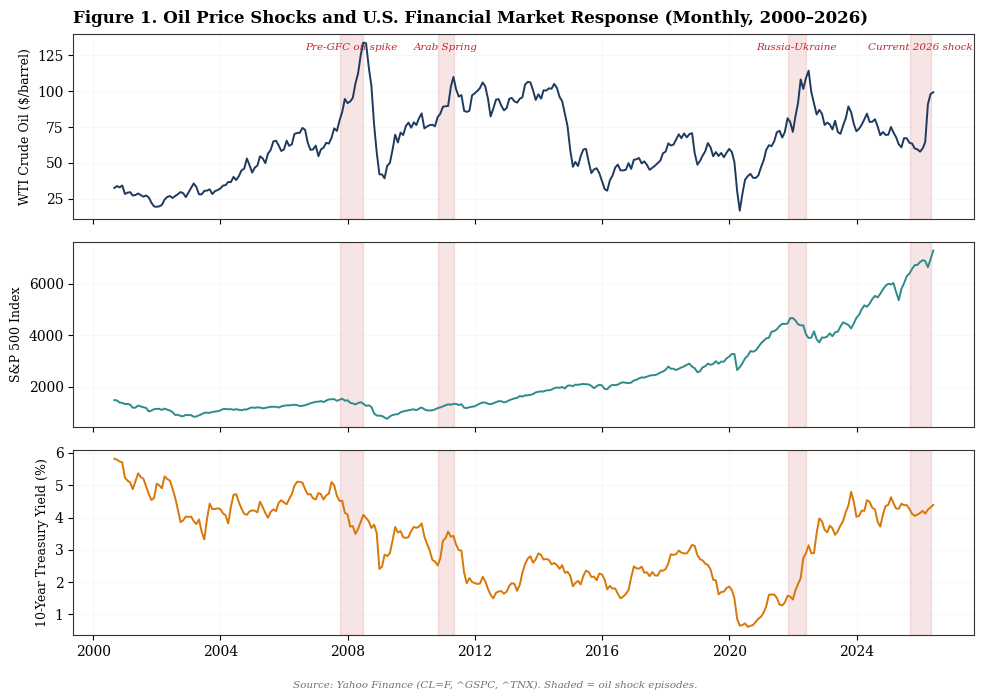

In [13]:
shocks = [
    ('2007-10', '2008-07', 'Pre-GFC oil spike'),
    ('2010-11', '2011-05', 'Arab Spring'),
    ('2021-11', '2022-06', 'Russia-Ukraine'),
    ('2025-09', '2026-05', 'Current 2026 shock'),
]

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, var, label, color in zip(axes,
        ['WTI','SP500','Treas10Y'],
        ['WTI Crude Oil ($/barrel)','S&P 500 Index','10-Year Treasury Yield (%)'],
        [NAVY, TEAL, ORANGE]):
    ax.plot(monthly.index, monthly[var], color=color, linewidth=1.4)
    ax.set_ylabel(label, fontsize=9)
    ax.grid(True, alpha=0.4)
    for start, end, _ in shocks:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=RED, alpha=0.12)

axes[0].set_title('Figure 1. Oil Price Shocks and U.S. Financial Market Response (Monthly, 2000–2026)', loc='left', pad=8)
for start, end, lbl in shocks:
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    axes[0].text(mid, axes[0].get_ylim()[1]*0.92, lbl, fontsize=7.5, ha='center', color=RED, style='italic')

fig.text(0.5, 0.01, 'Source: Yahoo Finance (CL=F, ^GSPC, ^TNX). Shaded = oil shock episodes.',
         ha='center', fontsize=7.5, style='italic', color=GRAY)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('fig1_timeseries.png', dpi=170, bbox_inches='tight')
plt.show()


### Figure 2. AS-AD test — Oil YoY vs U.S. inflation

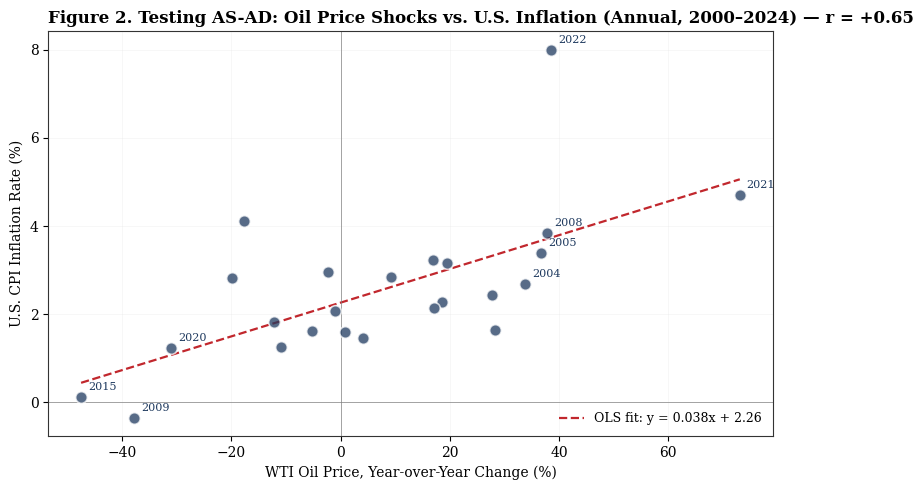

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(us['WTI_yoy'], us['Inflation_pct'], s=70, color=NAVY, alpha=0.75,
           edgecolor='white', linewidth=1.2, zorder=3)

mask = us[['WTI_yoy','Inflation_pct']].dropna()
slope, intercept = np.polyfit(mask['WTI_yoy'], mask['Inflation_pct'], 1)
x_line = np.linspace(mask['WTI_yoy'].min(), mask['WTI_yoy'].max(), 100)
ax.plot(x_line, slope*x_line + intercept, color=RED, linewidth=1.6, linestyle='--', zorder=2,
        label=f'OLS fit: y = {slope:.3f}x + {intercept:.2f}')

for _, row in us.iterrows():
    if pd.notna(row['WTI_yoy']) and abs(row['WTI_yoy']) > 30:
        ax.annotate(str(int(row['year'])), xy=(row['WTI_yoy'], row['Inflation_pct']),
                    xytext=(5,5), textcoords='offset points', fontsize=8, color=NAVY)

ax.axhline(0, color='gray', linewidth=0.5); ax.axvline(0, color='gray', linewidth=0.5)
r = mask['WTI_yoy'].corr(mask['Inflation_pct'])
ax.set_xlabel('WTI Oil Price, Year-over-Year Change (%)')
ax.set_ylabel('U.S. CPI Inflation Rate (%)')
ax.set_title(f'Figure 2. Testing AS-AD: Oil Price Shocks vs. U.S. Inflation (Annual, 2000–2024) — r = {r:+.2f}', loc='left')
ax.legend(loc='lower right', frameon=False, fontsize=9); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig2_oil_inflation.png', dpi=170, bbox_inches='tight')
plt.show()


### Figure 3. U.S. Debt/GDP vs 10Y Treasury — the crowding-out reversal

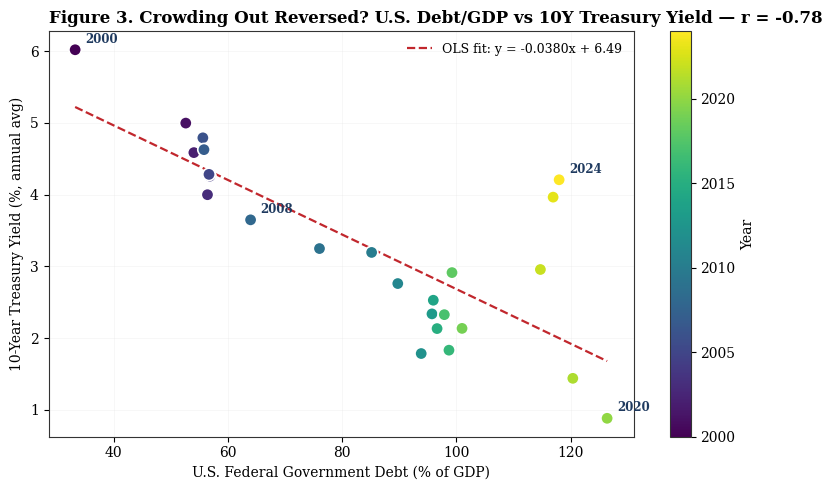

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
mask = us[['Debt_GDP_pct','Treas10Y_avg','year']].dropna()
sc = ax.scatter(mask['Debt_GDP_pct'], mask['Treas10Y_avg'], c=mask['year'],
                cmap='viridis', s=80, edgecolor='white', linewidth=1.2, zorder=3)

slope, intercept = np.polyfit(mask['Debt_GDP_pct'], mask['Treas10Y_avg'], 1)
x_line = np.linspace(mask['Debt_GDP_pct'].min(), mask['Debt_GDP_pct'].max(), 100)
ax.plot(x_line, slope*x_line + intercept, color=RED, linewidth=1.6, linestyle='--', zorder=2,
        label=f'OLS fit: y = {slope:.4f}x + {intercept:.2f}')

for _, row in mask.iterrows():
    if int(row['year']) in [2000, 2008, 2020, 2024]:
        ax.annotate(str(int(row['year'])), xy=(row['Debt_GDP_pct'], row['Treas10Y_avg']),
                    xytext=(7,5), textcoords='offset points', fontsize=8.5, fontweight='bold', color=NAVY)

plt.colorbar(sc, ax=ax, label='Year')
r = mask['Debt_GDP_pct'].corr(mask['Treas10Y_avg'])
ax.set_xlabel('U.S. Federal Government Debt (% of GDP)')
ax.set_ylabel('10-Year Treasury Yield (%, annual avg)')
ax.set_title(f'Figure 3. Crowding Out Reversed? U.S. Debt/GDP vs 10Y Treasury Yield — r = {r:+.2f}', loc='left')
ax.legend(loc='upper right', frameon=False, fontsize=9); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig3_debt_rates.png', dpi=170, bbox_inches='tight')
plt.show()


### Figure 4. Cross-country evidence: Debt/GDP vs GDP growth

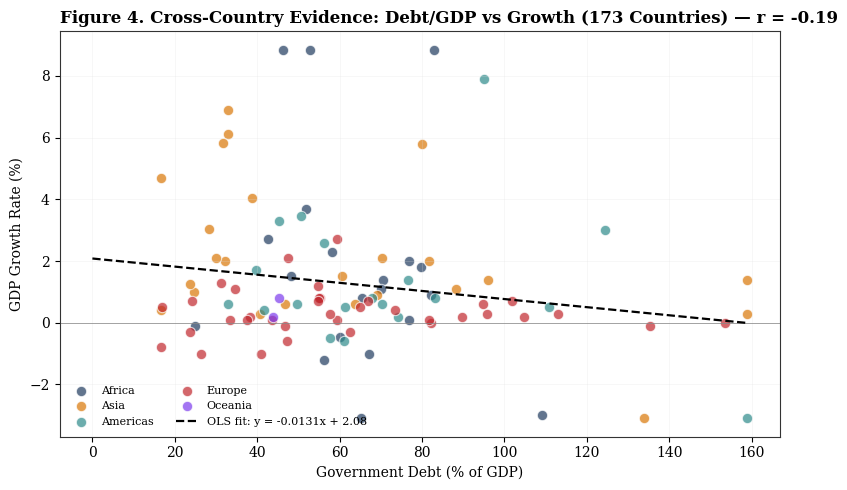

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
region_colors = {'Africa': NAVY, 'Americas': TEAL, 'Asia': ORANGE, 'Europe': RED, 'Oceania': '#7c3aed'}
for region in cc['region'].dropna().unique():
    sub = cc[cc['region'] == region]
    ax.scatter(sub['Debt/GDP'], sub['GDP Growth'], s=55, alpha=0.7,
               color=region_colors.get(region, GRAY), label=region,
               edgecolor='white', linewidth=0.8)

mask = cc[['Debt/GDP','GDP Growth']].dropna()
slope, intercept = np.polyfit(mask['Debt/GDP'], mask['GDP Growth'], 1)
x_line = np.linspace(0, mask['Debt/GDP'].max(), 100)
ax.plot(x_line, slope*x_line + intercept, color='black', linewidth=1.6, linestyle='--', zorder=4,
        label=f'OLS fit: y = {slope:.4f}x + {intercept:.2f}')

r = mask['Debt/GDP'].corr(mask['GDP Growth'])
ax.axhline(0, color='gray', linewidth=0.5)
ax.set_xlabel('Government Debt (% of GDP)'); ax.set_ylabel('GDP Growth Rate (%)')
ax.set_title(f'Figure 4. Cross-Country Evidence: Debt/GDP vs Growth (173 Countries) — r = {r:+.2f}', loc='left')
ax.legend(loc='lower left', frameon=False, fontsize=8, ncol=2); ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('fig4_crosscountry.png', dpi=170, bbox_inches='tight')
plt.show()


## 6. Lead-lag analysis (oil shock → equities)

In [17]:
lags = [0, 1, 3, 6, 9, 12, 18, 24]
print(f'{"Lag (months)":<14} {"WTI → S&P 500":<18} {"WTI → 10Y Treas":<18}')
print('-' * 55)
for k in lags:
    if k == 0:
        rs = monthly['WTI_yoy_pct'].corr(monthly['SP500_yoy_pct'])
        rt = monthly['WTI_yoy_pct'].corr(monthly['Treas10Y_yoy_bp'])
    else:
        rs = monthly['WTI_yoy_pct'].corr(monthly['SP500_yoy_pct'].shift(-k))
        rt = monthly['WTI_yoy_pct'].corr(monthly['Treas10Y_yoy_bp'].shift(-k))
    print(f'{k:<14} {rs:>+.3f}              {rt:>+.3f}')


Lag (months)   WTI → S&P 500      WTI → 10Y Treas   
-------------------------------------------------------
0              +0.360              +0.314
1              +0.287              +0.307
3              +0.098              +0.206
6              -0.112              +0.152
9              -0.252              +0.137
12             -0.348              +0.142
18             -0.173              +0.262
24             -0.011              -0.087


## 7. Excel outputs

In [18]:
# Save the analytical datasets to CSV for the Excel build pipeline
us.to_csv('us_annual.csv', index=False)
monthly.to_csv('merged_monthly.csv')
cc.to_csv('crosscountry_clean.csv', index=False)

print(f'us_annual.csv         {us.shape}')
print(f'merged_monthly.csv    {monthly.shape}')
print(f'crosscountry_clean.csv {cc.shape}')


us_annual.csv         (27, 11)
merged_monthly.csv    (310, 7)
crosscountry_clean.csv (101, 8)
